In [31]:
import pandas as pd
import glob
import os

# Find all sweep CSV files in the data directory
csv_files = sorted(glob.glob("../data/sweep_*.csv"))

if not csv_files:
    print("No sweep CSV files found in the 'data/' directory.")
else:
    dataframes = {}
    for file in csv_files:
        filename = os.path.basename(file)
        # comment='#' automatically skips the metadata lines
        df = pd.read_csv(file, comment='#')
        dataframes[filename] = df
        
        # Print a quick summary of what was loaded
        freqs = df['freq_hz'].unique()
        print(f"✅ Loaded: {filename}")
        print(f"   Rows: {len(df)} | Frequencies: {len(freqs)} ({freqs[0]:.0f} to {freqs[-1]:.0f} Hz)\n")

# To access a specific file later, use: 
# df = dataframes['sweep_xiao_20261016_144657_50step.csv']

✅ Loaded: sweep_xiao_20261016_122345_10step.csv
   Rows: 301205 | Frequencies: 100 (10 to 1000 Hz)

✅ Loaded: sweep_xiao_20261016_144327_5step.csv
   Rows: 575279 | Frequencies: 199 (10 to 1000 Hz)

✅ Loaded: sweep_xiao_20261016_144548_20step.csv
   Rows: 166245 | Frequencies: 50 (10 to 990 Hz)

✅ Loaded: sweep_xiao_20261016_144657_50step.csv
   Rows: 89230 | Frequencies: 20 (10 to 960 Hz)

✅ Loaded: sweep_xioa_20261016_123137_1step.csv
   Rows: 2778878 | Frequencies: 991 (10 to 1000 Hz)



In [32]:
import matplotlib.pyplot as plt
import numpy as np

def plot_reconstructed_signals(df, max_plots=9):
    """
    Plots measured vs ideal reconstructed signal for each frequency segment.
    """
    frequencies = sorted(df['freq_hz'].unique())
    n_freqs = min(len(frequencies), max_plots)
    
    cols = 3
    rows = (n_freqs + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
    
    # Flatten axes array for easy iteration, handle edge case of 1 plot
    if n_freqs == 1:
        axes = [axes]
    else:
        axes = axes.flatten()
    
    for i, freq in enumerate(frequencies[:max_plots]):
        ax = axes[i]
        segment = df[df['freq_hz'] == freq]
        
        # Normalize time to start at 0 ms for this specific segment for cleaner viewing
        t_rel = segment['time_ms'] - segment['time_ms'].iloc[0]
        
        # Plot Ideal vs Measured
        ax.plot(t_rel, segment['gen_ref_v'], label='Ideal (gen_ref_v)', color='gray', linestyle='--', linewidth=1.5)
        ax.plot(t_rel, segment['adc_v'], label='Measured (adc_v)', color='tab:blue', marker='.', markersize=2, linewidth=1)
        
        ax.set_title(f"Reconstruction: {freq:.1f} Hz")
        ax.set_xlabel("Time (ms)")
        ax.set_ylabel("Voltage (V)")
        ax.legend(loc='upper right', fontsize=8)
        ax.grid(True, alpha=0.3)
    
    # Hide any unused subplots
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')
        
    plt.suptitle("Signal Reconstruction: Measured ADC vs Ideal Generator Reference", fontsize=14, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

# Example usage (uncomment the file you want to analyze):
# plot_reconstructed_signals(dataframes['sweep_xiao_20261016_144657_50step.csv'], max_plots=9)

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import rfft, rfftfreq

def analyze_fft_and_spectrogram(df, target_freq_for_detail=510.0):
    """
    Analyzes FFT quality across the sweep and generates a 2D Spectrogram 
    to show all frequencies in a single, comprehensive plot.
    """
    frequencies = sorted(df['freq_hz'].unique())
    
    # --- PART 1: Summary Table ---
    print(f"{'Target Freq (Hz)':<15} | {'Detected Peak (Hz)':<18} | {'Magnitude (V)':<15} | {'Error (Hz)':<10}")
    print("-" * 65)
    
    # Arrays to store data for the Spectrogram
    spectrogram_magnitudes_interp = []
    f_common = np.arange(0, 1500, 1) # Common axis: 0 to 1500 Hz, 1 Hz resolution
    
    for freq in frequencies:
        segment = df[df['freq_hz'] == freq].copy()
        
        # Calculate actual sampling rate from time steps
        dt_ms = segment['time_ms'].diff().dropna().mean()
        fs = 1000.0 / dt_ms  
        N = len(segment)
        
        # Remove DC offset for cleaner FFT
        adc_signal = segment['adc_v'].values - np.mean(segment['adc_v'].values)
        
        # Compute FFT
        yf = rfft(adc_signal)
        xf = rfftfreq(N, d=(1.0/fs))
        magnitude = np.abs(yf) / N
        
        # INTERPOLATE onto the common frequency axis so all arrays have the same length
        mag_interp = np.interp(f_common, xf, magnitude)
        spectrogram_magnitudes_interp.append(mag_interp)
        
        # Find peak (skip index 0 which is DC)
        peak_idx = np.argmax(magnitude[1:]) + 1  
        peak_freq = xf[peak_idx]
        peak_mag = magnitude[peak_idx]
        error = abs(peak_freq - freq)
        
        print(f"{freq:<15.1f} | {peak_freq:<18.2f} | {peak_mag:<15.4f} | {error:<10.2f}")

    # --- PART 2: Single Clean FFT Plot (for spectral purity proof) ---
    detail_segment = df[df['freq_hz'] == target_freq_for_detail].copy()
    dt_ms = detail_segment['time_ms'].diff().dropna().mean()
    fs = 1000.0 / dt_ms
    N = len(detail_segment)
    
    yf_detail = rfft(detail_segment['adc_v'].values - np.mean(detail_segment['adc_v'].values))
    xf_detail = rfftfreq(N, d=(1.0/fs))
    mag_detail = np.abs(yf_detail) / N
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Plot 1: Clean FFT of a single frequency
    ax1.plot(xf_detail, mag_detail, color='tab:blue', linewidth=1.5)
    ax1.axvline(target_freq_for_detail, color='red', linestyle='--', label=f'Target: {target_freq_for_detail} Hz')
    ax1.set_title(f"FFT Spectral Purity at {target_freq_for_detail} Hz")
    ax1.set_xlabel("Frequency (Hz)")
    ax1.set_ylabel("Magnitude (V)")
    ax1.set_xlim(0, fs / 2)
    ax1.grid(True, alpha=0.3)
    ax1.legend()
    
    # --- PART 3: 2D Spectrogram Heatmap (All frequencies in one plot) ---
    # Now that all arrays are interpolated to the same length, we can stack them!
    spectrogram_magnitudes = np.array(spectrogram_magnitudes_interp)
    
    # Plot 2: Spectrogram
    c = ax2.pcolormesh(f_common, frequencies, spectrogram_magnitudes, shading='auto', cmap='magma')
    ax2.set_title("Full Sweep Spectrogram (All Frequencies in One Plot)")
    ax2.set_xlabel("Frequency (Hz)")
    ax2.set_ylabel("Target Sweep Frequency (Hz)")
    
    # Add a diagonal line to show perfect tracking
    ax2.plot(frequencies, frequencies, color='cyan', linestyle=':', linewidth=2, label='Ideal Tracking')
    
    ax2.set_xlim(0, 1500)
    ax2.set_ylim(frequencies[0], frequencies[-1])
    ax2.grid(True, alpha=0.3)
    ax2.legend()
    
    fig.colorbar(c, ax=ax2, label='Magnitude (V)')
    
    plt.suptitle("Fourier Transform Analysis: Reconstruction Quality", fontsize=14, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

In [39]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

def analyze_residuals_and_stats(df, target_freqs=None):
    """
    Calculates reconstruction statistics (RMSE, R-squared, SNR) and 
    plots the residuals (ADC - Ideal) to visualize deviation.
    """
    frequencies = sorted(df['freq_hz'].unique())
    
    # If no specific frequencies are requested, pick low, mid, and high
    if target_freqs is None:
        target_freqs = [frequencies[0], frequencies[len(frequencies)//2], frequencies[-1]]
    
    # Ensure requested frequencies actually exist in the data
    target_freqs = [f for f in target_freqs if f in frequencies]
    
    print(f"{'Freq (Hz)':<10} | {'RMSE (V)':<10} | {'Variance':<10} | {'R-squared':<10} | {'SNR (dB)':<10}")
    print("-" * 65)
    
    stats_list = []
    
    # Create a grid for plotting: 2 rows (Signal + Residual) x N columns (for each target freq)
    fig, axes = plt.subplots(2, len(target_freqs), figsize=(5 * len(target_freqs), 6))
    if len(target_freqs) == 1:
        axes = np.array([[axes[0]], [axes[1]]]) # Force 2D array for consistent indexing
    
    for col, freq in enumerate(target_freqs):
        segment = df[df['freq_hz'] == freq].copy()
        
        # Normalize time to start at 0 ms for this segment
        t_rel = segment['time_ms'] - segment['time_ms'].iloc[0]
        adc_v = segment['adc_v'].values
        ref_v = segment['gen_ref_v'].values
        
        # 1. Calculate Residuals
        residuals = adc_v - ref_v
        
        # 2. Calculate Statistics
        rmse = np.sqrt(np.mean(residuals**2))
        variance = np.var(residuals)
        
        # R-squared (Coefficient of Determination)
        ss_res = np.sum(residuals**2)
        ss_tot = np.sum((ref_v - np.mean(ref_v))**2)
        r_squared = 1 - (ss_res / ss_tot) if ss_tot != 0 else 0.0
        
        # Signal-to-Noise Ratio (SNR) in dB
        # Signal power = variance of ideal reference, Noise power = variance of residuals
        signal_power = np.var(ref_v)
        noise_power = variance if variance > 0 else 1e-10
        snr_db = 10 * np.log10(signal_power / noise_power)
        
        stats_list.append({
            'Freq_Hz': freq, 'RMSE_V': rmse, 'Variance': variance, 
            'R_Squared': r_squared, 'SNR_dB': snr_db
        })
        
        print(f"{freq:<10.1f} | {rmse:<10.4f} | {variance:<10.4f} | {r_squared:<10.4f} | {snr_db:<10.2f}")
        
        # --- PLOTTING ---
        # Top row: Overlay of Ideal vs Measured
        ax_top = axes[0, col]
        ax_top.plot(t_rel, ref_v, label='Ideal (gen_ref_v)', color='gray', linestyle='--', linewidth=1.5)
        ax_top.plot(t_rel, adc_v, label='Measured (adc_v)', color='tab:blue', marker='.', markersize=2, linewidth=1)
        ax_top.set_title(f"Reconstruction: {freq:.1f} Hz")
        ax_top.set_ylabel("Voltage (V)")
        ax_top.legend(loc='upper right', fontsize=8)
        ax_top.grid(True, alpha=0.3)
        
        # Bottom row: Residuals (Deviation)
        ax_bot = axes[1, col]
        ax_bot.plot(t_rel, residuals, color='tab:red', linewidth=1, alpha=0.8)
        ax_bot.axhline(0, color='black', linestyle='-', linewidth=1)
        
        # Add +/- 1 Standard Deviation bands
        std_dev = np.std(residuals)
        ax_bot.axhline(std_dev, color='orange', linestyle=':', label=f'±1σ ({std_dev:.3f}V)')
        ax_bot.axhline(-std_dev, color='orange', linestyle=':')
        
        ax_bot.set_title(f"Residuals (ADC - Ideal)")
        ax_bot.set_xlabel("Time in segment (ms)")
        ax_bot.set_ylabel("Error (V)")
        ax_bot.legend(loc='upper right', fontsize=8)
        ax_bot.grid(True, alpha=0.3)

    plt.suptitle("Statistical Analysis: Reconstruction Quality & Residuals", fontsize=14, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()
    
    return pd.DataFrame(stats_list)

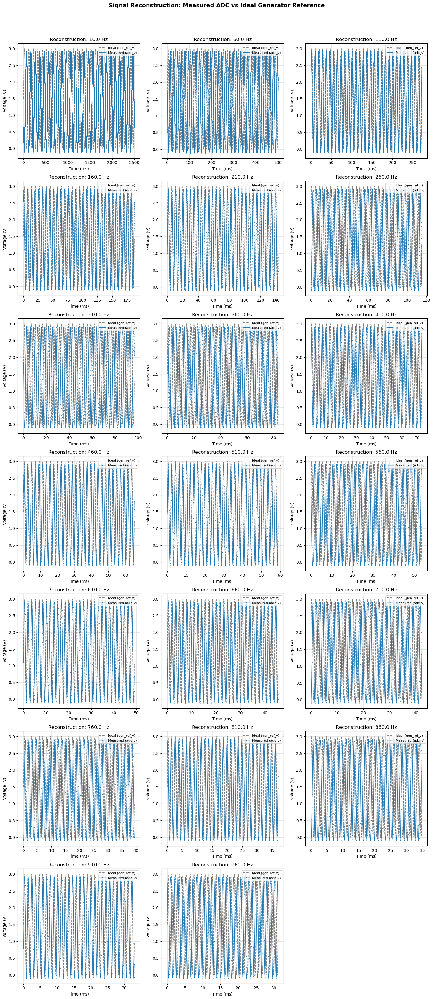

In [ ]:
plot_reconstructed_signals(dataframes['sweep_xiao_20261016_144657_50step.csv'], 20)

Target Freq (Hz) | Detected Peak (Hz) | Magnitude (V)   | Error (Hz)
-----------------------------------------------------------------
10.0            | 10.00              | 0.7511          | 0.00      
60.0            | 60.00              | 0.7509          | 0.00      
110.0           | 110.01             | 0.7510          | 0.01      
160.0           | 160.00             | 0.7508          | 0.00      
210.0           | 210.01             | 0.7510          | 0.01      
260.0           | 260.08             | 0.7509          | 0.08      
310.0           | 310.08             | 0.7510          | 0.08      
360.0           | 360.14             | 0.7508          | 0.14      
410.0           | 410.12             | 0.7509          | 0.12      
460.0           | 460.12             | 0.7508          | 0.12      
510.0           | 510.20             | 0.7507          | 0.20      
560.0           | 560.22             | 0.7506          | 0.22      
610.0           | 610.38             | 0.7505    

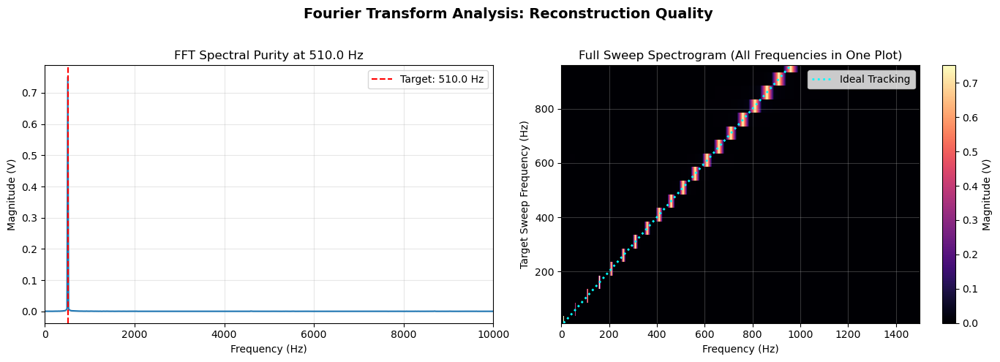

In [35]:
analyze_fft_and_spectrogram(dataframes['sweep_xiao_20261016_144657_50step.csv'], target_freq_for_detail=510.0)

Freq (Hz)  | RMSE (V)   | Variance   | R-squared  | SNR (dB)  
-----------------------------------------------------------------
10.0       | 2.0467     | 4.1805     | -2.7237    | -5.70     
60.0       | 2.1153     | 4.4659     | -2.9775    | -5.99     
210.0      | 0.3086     | 0.0865     | 0.9154     | 11.14     
260.0      | 1.7196     | 2.9482     | -1.6275    | -4.18     


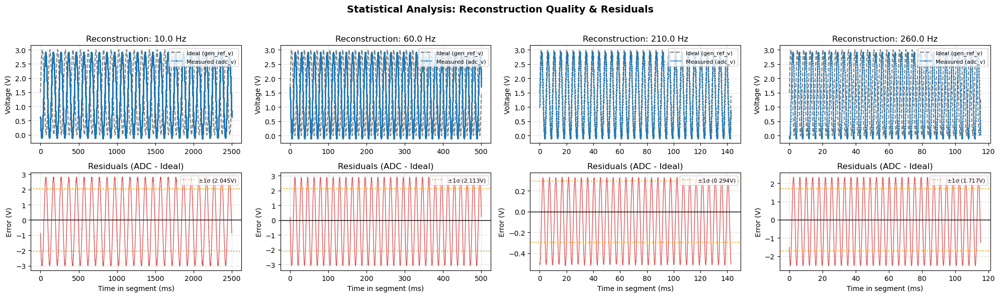

In [44]:
# Example usage: Analyze low (10 Hz), mid (510 Hz), and high (960 Hz) frequencies
# (Change these numbers to match frequencies that actually exist in your specific CSV file)
stats_df = analyze_residuals_and_stats(
    dataframes['sweep_xiao_20261016_144657_50step.csv'], 
    target_freqs=[10.0, 60.0, 210.0, 260.0]
)

Freq (Hz)  | RMSE (V)   | Variance   | R-squared  | SNR (dB)  
-----------------------------------------------------------------
310.0      | 2.1016     | 4.4081     | -2.9252    | -5.93     
360.0      | 1.8512     | 3.4183     | -2.0451    | -4.82     
410.0      | 1.2368     | 1.5209     | -0.3594    | -1.31     
460.0      | 0.4924     | 0.2336     | 0.7845     | 6.83      


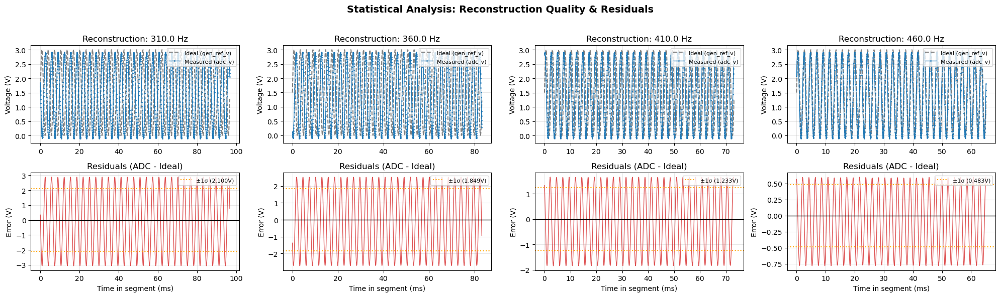

In [45]:
stats_df = analyze_residuals_and_stats(
    dataframes['sweep_xiao_20261016_144657_50step.csv'], 
    target_freqs=[310.0, 360.0, 410.0, 460.0]
)

Freq (Hz)  | RMSE (V)   | Variance   | R-squared  | SNR (dB)  
-----------------------------------------------------------------
510.0      | 0.0945     | 0.0002     | 0.9921     | 38.27     
560.0      | 1.8379     | 3.3691     | -2.0015    | -4.76     
610.0      | 0.2366     | 0.0471     | 0.9503     | 13.79     
660.0      | 0.7965     | 0.6258     | 0.4361     | 2.55      


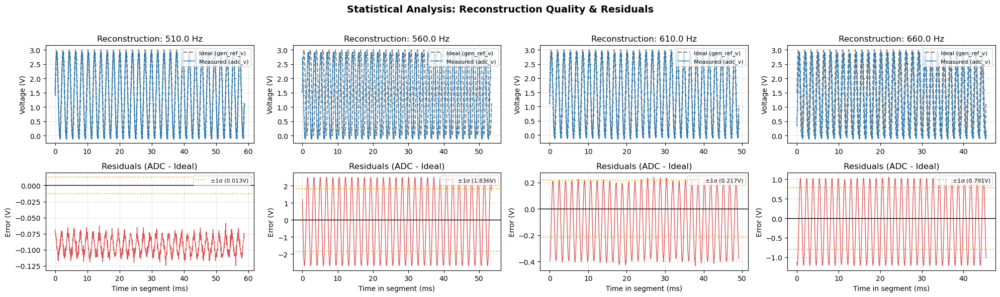

In [46]:
stats_df = analyze_residuals_and_stats(
    dataframes['sweep_xiao_20261016_144657_50step.csv'], 
    target_freqs=[510.0, 560.0, 610.0, 660.0]
)

Freq (Hz)  | RMSE (V)   | Variance   | R-squared  | SNR (dB)  
-----------------------------------------------------------------
710.0      | 1.7761     | 3.1462     | -1.8040    | -4.47     
760.0      | 1.5280     | 2.3264     | -1.0742    | -3.15     
810.0      | 0.7671     | 0.5796     | 0.4774     | 2.88      
860.0      | 1.9174     | 3.6679     | -2.2651    | -5.13     
910.0      | 0.4632     | 0.2061     | 0.8093     | 7.37      
960.0      | 1.8348     | 3.3577     | -1.9923    | -4.75     


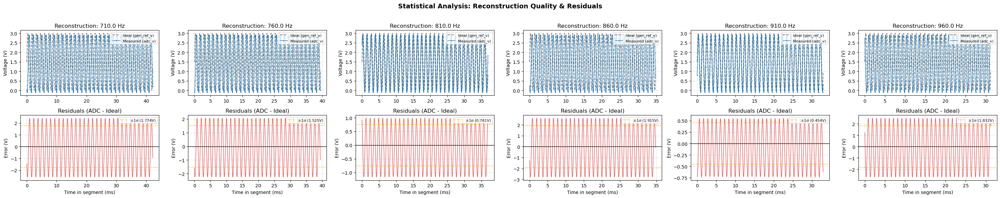

In [47]:
stats_df = analyze_residuals_and_stats(
    dataframes['sweep_xiao_20261016_144657_50step.csv'], 
    target_freqs=[ 710.0, 760.0, 810.0, 860.0, 910.0, 960.0]
)




In [37]:
plot_reconstructed_signals(dataframes['sweep_xiao_20261016_122345_10step.csv'], 100)

Target Freq (Hz) | Detected Peak (Hz) | Magnitude (V)   | Error (Hz)
-----------------------------------------------------------------
10.0            | 10.00              | 0.7512          | 0.00      
20.0            | 20.00              | 0.7510          | 0.00      
30.0            | 30.00              | 0.7506          | 0.00      
40.0            | 40.00              | 0.7513          | 0.00      
50.0            | 50.00              | 0.7508          | 0.00      
60.0            | 60.00              | 0.7507          | 0.00      
70.0            | 70.00              | 0.7515          | 0.00      
80.0            | 80.00              | 0.7513          | 0.00      
90.0            | 90.01              | 0.7510          | 0.01      
100.0           | 100.00             | 0.7512          | 0.00      
110.0           | 110.01             | 0.7513          | 0.01      
120.0           | 120.00             | 0.7511          | 0.00      
130.0           | 130.01             | 0.7512    

/tmp/ipykernel_765925/367295852.py:91: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


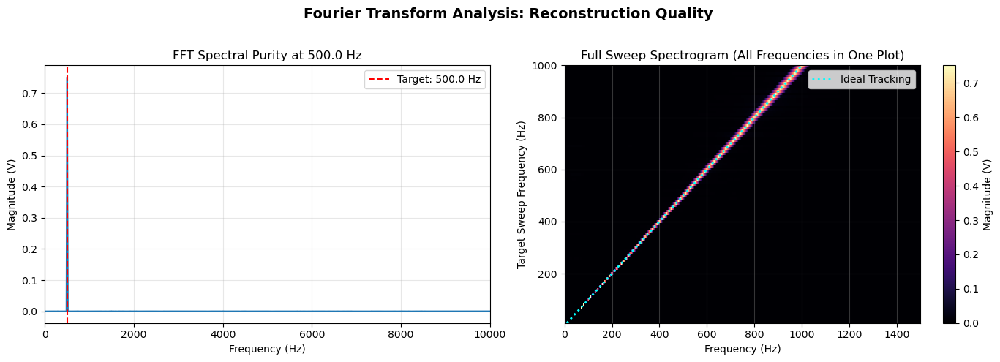

In [38]:
analyze_fft_and_spectrogram(dataframes['sweep_xiao_20261016_122345_10step.csv'], 500.0)

Freq (Hz)  | RMSE (V)   | Variance   | R-squared  | SNR (dB)  
-----------------------------------------------------------------
10.0       | 0.2368     | 0.0472     | 0.9501     | 13.77     
20.0       | 0.5228     | 0.2643     | 0.7570     | 6.29      
30.0       | 1.3895     | 1.9218     | -0.7162    | -2.33     
40.0       | 2.0680     | 4.2678     | -2.8013    | -5.79     


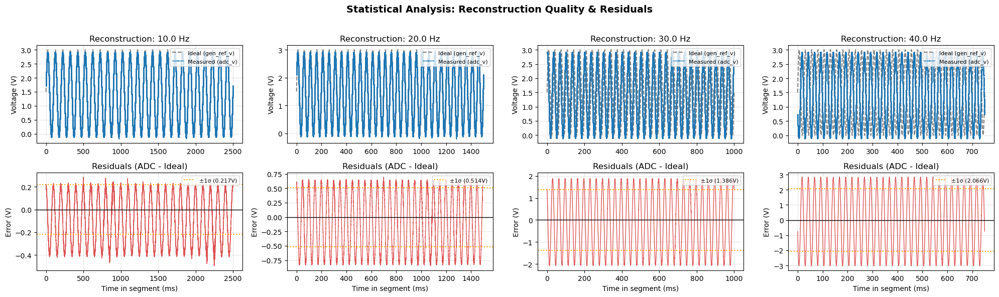

In [48]:
stats_df = analyze_residuals_and_stats(
    dataframes['sweep_xiao_20261016_122345_10step.csv'], 
    target_freqs=[10.0, 20.0, 30.0, 40.0]
)

Freq (Hz)  | RMSE (V)   | Variance   | R-squared  | SNR (dB)  
-----------------------------------------------------------------
50.0       | 1.0866     | 1.1719     | -0.0496    | -0.18     
60.0       | 1.8618     | 3.4574     | -2.0812    | -4.88     
70.0       | 2.1102     | 4.4440     | -2.9579    | -5.97     
80.0       | 0.4556     | 0.1987     | 0.8155     | 7.53      


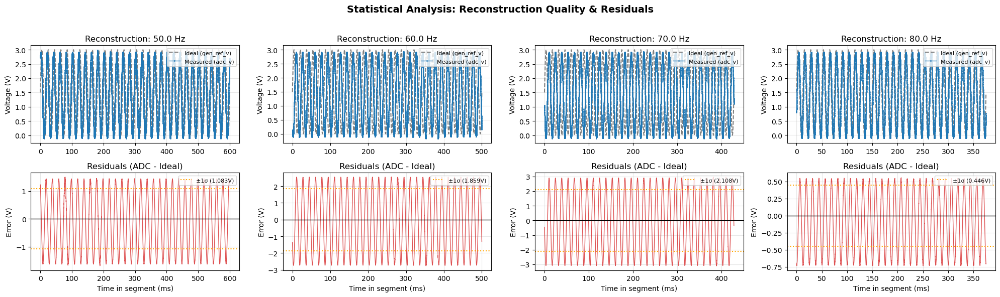

In [49]:
stats_df = analyze_residuals_and_stats(
    dataframes['sweep_xiao_20261016_122345_10step.csv'], 
    target_freqs=[50.0, 60.0, 70.0, 80.0]
)

Freq (Hz)  | RMSE (V)   | Variance   | R-squared  | SNR (dB)  
-----------------------------------------------------------------
90.0       | 1.2619     | 1.5835     | -0.4152    | -1.48     
100.0      | 1.6993     | 2.8788     | -1.5666    | -4.08     
110.0      | 1.9830     | 3.9234     | -2.4949    | -5.42     
120.0      | 2.1064     | 4.4281     | -2.9439    | -5.95     


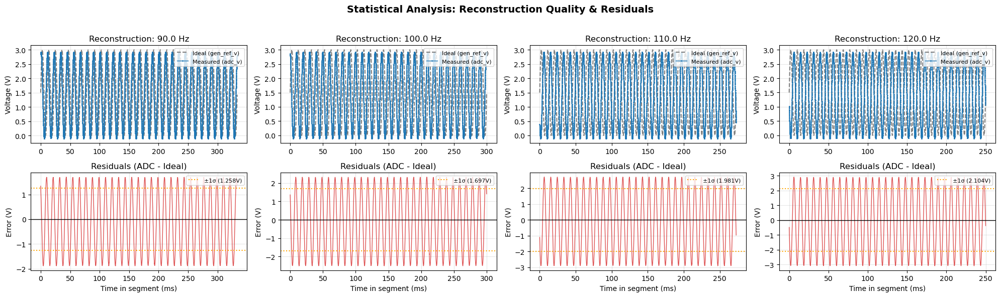

In [50]:
stats_df = analyze_residuals_and_stats(
    dataframes['sweep_xiao_20261016_122345_10step.csv'], 
    target_freqs=[90.0, 100.0, 110.0, 120.0]
)

Freq (Hz)  | RMSE (V)   | Variance   | R-squared  | SNR (dB)  
-----------------------------------------------------------------
100.0      | 1.6993     | 2.8788     | -1.5666    | -4.08     
150.0      | 2.0878     | 4.3500     | -2.8746    | -5.87     
200.0      | 1.6623     | 2.7544     | -1.4562    | -3.89     
250.0      | 2.0215     | 4.0776     | -2.6323    | -5.59     


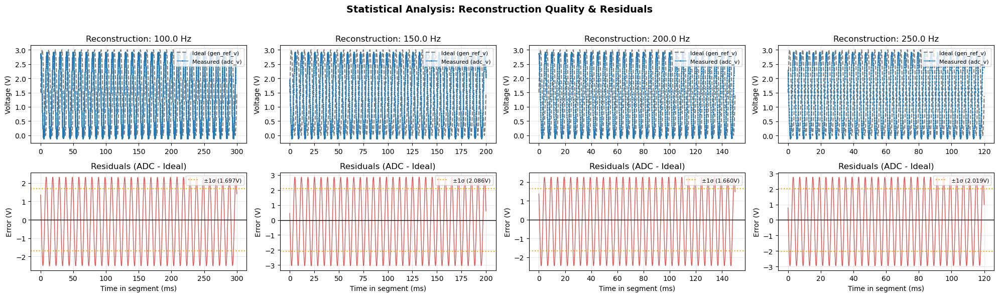

In [51]:
stats_df = analyze_residuals_and_stats(
    dataframes['sweep_xiao_20261016_122345_10step.csv'], 
    target_freqs=[100.0, 150.0, 200.0, 250.0]
)

Freq (Hz)  | RMSE (V)   | Variance   | R-squared  | SNR (dB)  
-----------------------------------------------------------------
300.0      | 0.2001     | 0.0313     | 0.9644     | 15.56     
350.0      | 1.1751     | 1.3718     | -0.2272    | -0.86     
400.0      | 0.2136     | 0.0370     | 0.9594     | 14.83     
450.0      | 1.5684     | 2.4511     | -1.1859    | -3.38     


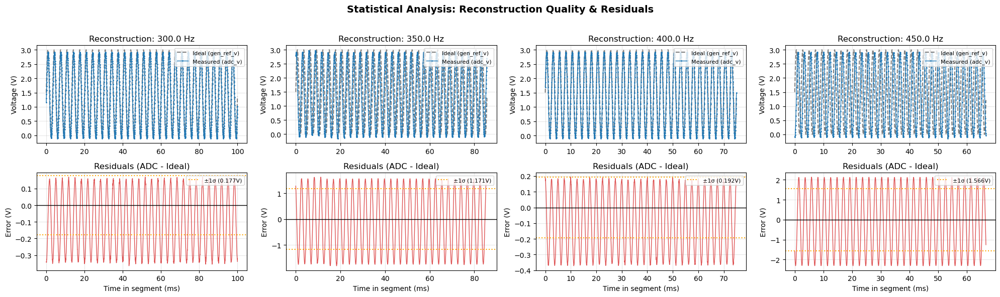

In [52]:
stats_df = analyze_residuals_and_stats(
    dataframes['sweep_xiao_20261016_122345_10step.csv'], 
    target_freqs=[300.0, 350.0, 400.0, 450.0]
)

Freq (Hz)  | RMSE (V)   | Variance   | R-squared  | SNR (dB)  
-----------------------------------------------------------------
500.0      | 0.9393     | 0.8735     | 0.2158     | 1.10      
550.0      | 2.1021     | 4.4100     | -2.9249    | -5.93     
600.0      | 1.8452     | 3.3959     | -2.0263    | -4.80     
650.0      | 1.7893     | 3.1926     | -1.8456    | -4.53     


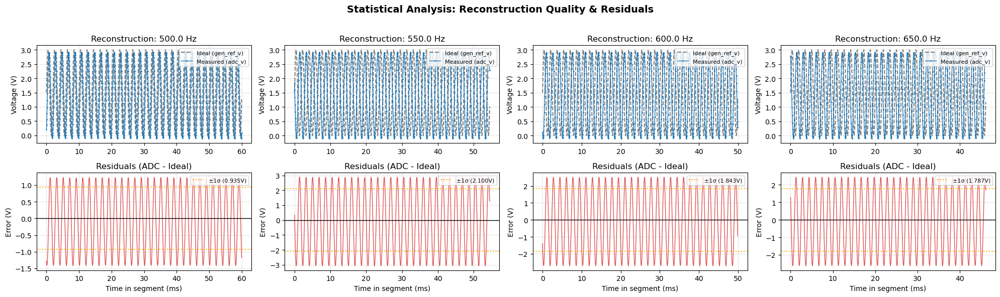

In [53]:
stats_df = analyze_residuals_and_stats(
    dataframes['sweep_xiao_20261016_122345_10step.csv'], 
    target_freqs=[500.0, 550.0, 600.0, 650.0]
)

Freq (Hz)  | RMSE (V)   | Variance   | R-squared  | SNR (dB)  
-----------------------------------------------------------------
700.0      | 1.5766     | 2.4770     | -1.2093    | -3.43     
750.0      | 0.1007     | 0.0013     | 0.9910     | 29.47     
800.0      | 2.0700     | 4.2762     | -2.8088    | -5.80     
850.0      | 0.1822     | 0.0246     | 0.9705     | 16.60     


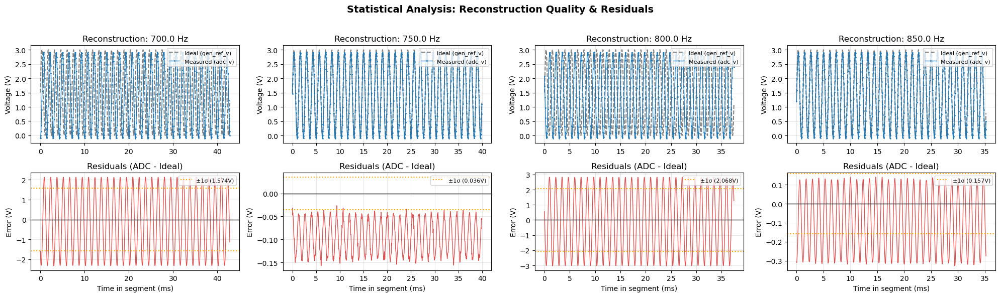

In [54]:
stats_df = analyze_residuals_and_stats(
    dataframes['sweep_xiao_20261016_122345_10step.csv'], 
    target_freqs=[700.0, 750.0, 800.0, 850.0]
)

Freq (Hz)  | RMSE (V)   | Variance   | R-squared  | SNR (dB)  
-----------------------------------------------------------------
900.0      | 0.0947     | 0.0004     | 0.9920     | 34.85     
950.0      | 0.1948     | 0.0292     | 0.9663     | 15.87     
1000.0     | 0.9825     | 0.9567     | 0.1419     | 0.70      


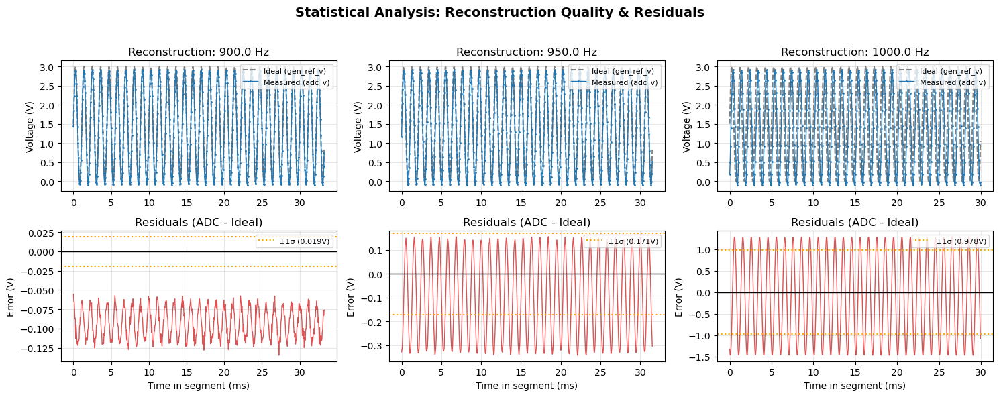

In [55]:
stats_df = analyze_residuals_and_stats(
    dataframes['sweep_xiao_20261016_122345_10step.csv'], 
    target_freqs=[900.0, 950.0, 1000.0]
)